NON LLM BASED CONDITIONAL WORKFLOW

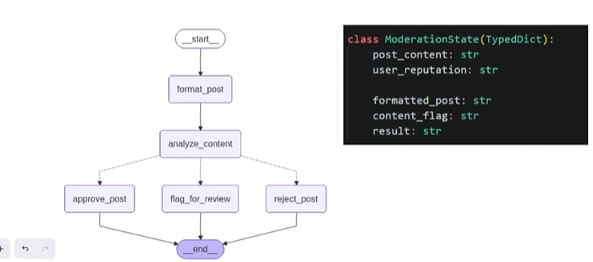

In [13]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict,Literal

Making states

In [3]:
class ModerationState(TypedDict):
    post_content:str 
    user_reputation:str 
    
    formatted_post:str
    content_flag:str 
    result:str 


Create Nodes 

In [6]:
def format_post(state:ModerationState):
    formatted=f"User {state['user_reputation'] } says: {state['post_content']}"
    return {'formatted_post':formatted} #only return updated state

In [7]:
def analyze_content(state:ModerationState):
    content=state['post_content'].lower()  #get the content and comvert it to lower case form

    #simple logic to analyze content
    if 'spam' in content or 'buy now' in content:
        flag='rejected'
    elif state['user_reputation']=='new_user':
        flag='review'
    else:
        flag='approved'
    
    return {'content_flag':flag}

In [8]:
def approve_post(state:ModerationState):
    result='post published successfully'
    return {'result':result}

In [9]:
def flag_for_review(state:ModerationState):
    result='Post sent for human evaluation'
    return {'result':result}

In [10]:
def reject_post(state:ModerationState):
    result='Post rejected'
    return {'result':result}

function for condition

In [ ]:
def check_condition(state:ModerationState)->Literal["approve_post","flag_for_review","reject_post"]: #based on condition any one node will be returned
    if state['content_flag']=='approved':
        return "approve_post" #this is a node
    elif state['content_flag']=='review':
        return "flag_for_review" #this is a node
    else:
        return "reject_post" #this is a node

Creating Graph

In [16]:
graph=StateGraph(ModerationState)

#add nodes 
graph.add_node("format_post",format_post)
graph.add_node("analyze_content",analyze_content)
graph.add_node("approve_post",approve_post)
graph.add_node("flag_for_review",flag_for_review)
graph.add_node("reject_post",reject_post)


#making edges

graph.add_edge(START,'format_post')
graph.add_edge('format_post','analyze_content')

#adding conditional edges
graph.add_conditional_edges('analyze_content',check_condition) #analyze content se start ho rhi conditions


graph.add_edge("approve_post",END)
graph.add_edge("flag_for_review",END)
graph.add_edge("reject_post",END)


In [17]:
workflow=graph.compile()

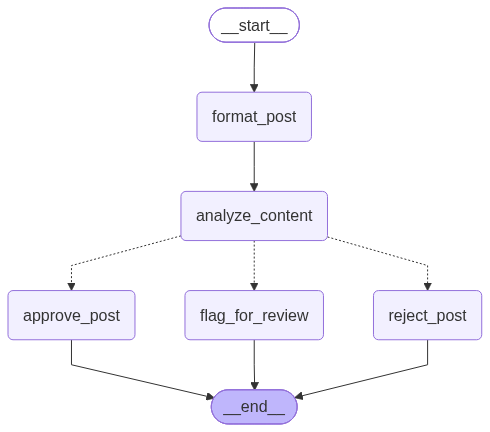

In [18]:
workflow

In [24]:
initial_state={
    'post_content':"Check out this amazing product. Buy now",
    'user_reputation':"trusted_user"
}

In [ ]:
workflow.invoke(initial_state) #rejected since it has keyword "Buy Now" in it

{'post_content': 'Check out this amazing product. Buy now',
 'user_reputation': 'trusted_user',
 'formatted_post': 'User trusted_user says: Check out this amazing product. Buy now',
 'content_flag': 'rejected',
 'result': 'Post rejected'}

LLM BASED CONDITIONAL WORKFLOW

Review Reply System-> user gives a review and we have to reply to that review.

In [28]:

from dotenv import load_dotenv

In [31]:
from pydantic import BaseModel,Field

In [29]:
load_dotenv()


True

In [30]:

from langchain_google_genai import ChatGoogleGenerativeAI

model = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash-lite",
    temperature=1.0,
)

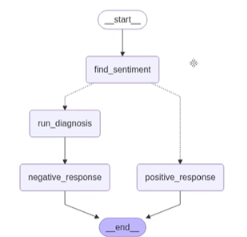

In [27]:
class ReviewState(TypedDict):
    review:str 
    sentiment:Literal["positive","negative"]
    diagnosis:dict
    response:str

Pydantic classes for structured O/Ps

In [32]:
class SentimentSchema(BaseModel):
    sentiment:Literal["positive","negative"]=Field(description='Sentiment of the review')

In [35]:
class DiagnosisSchema(BaseModel):
    issue_type:Literal["UX","Performance","Bug","Support","Other"]=Field(description="The category of issue mentioned in the review")
    tone:Literal["angry","frustated","disappointed","calm"]=Field(description="The emotional tone expressed by the user")
    urgency:Literal["low","medium","high"]=Field(description="How urgent or critical the issue appears to be")

In [37]:
structured_model=model.with_structured_output(SentimentSchema)

In [39]:
prompt='what is sentiment of following review Very bad Software'

structured_model.invoke(prompt).sentiment

c:\Users\Dell\Desktop\Generative AI\LangGraph\.conda\Lib\site-packages\langchain_google_genai\chat_models.py:3908: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


'negative'

In [40]:
structured_model2=model.with_structured_output(DiagnosisSchema)

In [42]:
prompt='what is sentiment of following review Very bad Software'

structured_model2.invoke(prompt)

c:\Users\Dell\Desktop\Generative AI\LangGraph\.conda\Lib\site-packages\langchain_google_genai\chat_models.py:3908: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


DiagnosisSchema(issue_type='Other', tone='disappointed', urgency='medium')

In [43]:
class ReviewState(TypedDict):

    review: str
    sentiment: Literal["positive", "negative"]
    diagnosis: dict
    response: str


Nodes ke functions

In [45]:
def find_sentiment(state: ReviewState):

    prompt = f'For the following review find out the sentiment \n {state["review"]}'
    sentiment = structured_model.invoke(prompt).sentiment

    return {'sentiment': sentiment}

In [46]:
def positive_response(state: ReviewState):

    prompt = f"""Write a warm thank-you message in response to this review:
    \n\n\"{state['review']}\"\n
Also, kindly ask the user to leave feedback on our website."""
    
    response = model.invoke(prompt).content

    return {'response': response}

In [47]:
def run_diagnosis(state: ReviewState):

    prompt = f"""Diagnose this negative review:\n\n{state['review']}\n"
    "Return issue_type, tone, and urgency.
"""
    response = structured_model2.invoke(prompt)

    return {'diagnosis': response.model_dump()}

In [48]:
def negative_response(state: ReviewState):

    diagnosis = state['diagnosis']

    prompt = f"""You are a support assistant.
The user had a '{diagnosis['issue_type']}' issue, sounded '{diagnosis['tone']}', and marked urgency as '{diagnosis['urgency']}'.
Write an empathetic, helpful resolution message.
"""
    response = model.invoke(prompt).content

    return {'response': response}

In [49]:
def check_sentiment(state: ReviewState) -> Literal["positive_response", "run_diagnosis"]:

    if state['sentiment'] == 'positive':
        return 'positive_response'
    else:
        return 'run_diagnosis'

In [50]:
graph=StateGraph(ReviewState)

# add nodes
graph.add_node('find_sentiment', find_sentiment)
graph.add_node('positive_response', positive_response)
graph.add_node('run_diagnosis', run_diagnosis)
graph.add_node('negative_response', negative_response)


# add edges with conditions
graph.add_edge(START, 'find_sentiment')
graph.add_conditional_edges('find_sentiment', check_sentiment)

graph.add_edge('positive_response', END)

graph.add_edge('run_diagnosis', 'negative_response')
graph.add_edge('negative_response', END)

workflow = graph.compile()

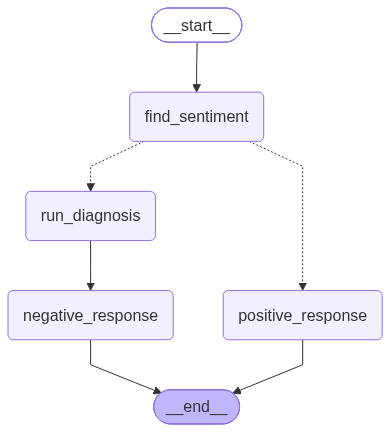

In [51]:
workflow


In [52]:
intial_state={
    'review': "Excellent software with a clean interface and smooth performance. It has improved our workflow significantly and saved a lot of time. Highly recommended for anyone looking for a reliable tech solution!"
}
result = workflow.invoke(intial_state)

c:\Users\Dell\Desktop\Generative AI\LangGraph\.conda\Lib\site-packages\langchain_google_genai\chat_models.py:3908: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
c:\Users\Dell\Desktop\Generative AI\LangGraph\.conda\Lib\site-packages\langchain_google_genai\chat_models.py:3908: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


In [53]:
result


{'review': 'Excellent software with a clean interface and smooth performance. It has improved our workflow significantly and saved a lot of time. Highly recommended for anyone looking for a reliable tech solution!',
 'sentiment': 'positive',
 'response': [{'type': 'text',
   'text': 'Here is a warm and professional response you can use:\n\n***\n\n"Thank you so much for the fantastic review! We are thrilled to hear that the clean interface and smooth performance have improved your workflow and saved you time—that is exactly what we strive for. \n\nIf you have a quick moment, we would love it if you could also share your experience on the feedback page of our website [insert link]. Testimonials like yours mean the world to our team and help others discover our solution. \n\nThanks again for choosing us and for your strong recommendation!"',
   'extras': {'signature': 'El4KXAERTTIPOArAKhZmhgcFEKWU9tAiQjjWLSkbgfGK8zdWO8ElyS96D7Fdlluqe9/Z3StYE/Kwx1r0kpYiuorOFHqnIujxDCxVIFsu33BMQYFFMWBIvALEW